# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Aditya Reyvano Bagaskara
- **Email:** adityareyvano@gmail.com
- **ID Dicoding:** GRX50QGN2Z0M

## Deskripsi Proyek
Analisis data penyewaan sepeda per jam pada periode 2011–2012 untuk memahami pola permintaan berdasarkan waktu, musim, dan kondisi cuaca.

## Menentukan Pertanyaan Bisnis

Pertanyaan berikut disusun dengan prinsip SMART: spesifik, terukur, dapat dijawab dengan dataset, relevan bagi keputusan operasional, dan dibatasi pada periode 2011–2012.

1. Pertanyaan 1: Bagaimana pola penyewaan sepeda berdasarkan jam selama periode 2011–2012, dan pada jam berapa total penyewaan mencapai nilai tertinggi dan terendah?
2. Pertanyaan 2 : Bagaimana rata-rata penyewaan sepeda per jam berbeda berdasarkan musim dan kondisi cuaca selama periode 2011–2012, dan kategori mana yang memiliki rata-rata tertinggi dan terendah?

Pertanyaan pertama mendukung perencanaan ketersediaan sepeda pada jam sibuk. Pertanyaan kedua membantu memahami perbedaan permintaan menurut kondisi lingkungan. Analisis deskriptif menunjukkan pola/asosiasi, bukan sebab-akibat.

## Import Semua Packages/Library yang Digunakan

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

possible_paths = [Path("data/hour.csv"), Path("hour.csv"), Path("../data/hour.csv")]
data_path = next((p for p in possible_paths if p.exists()), None)
if data_path is None:
    raise FileNotFoundError("hour.csv tidak ditemukan. Simpan dataset pada folder data/ atau bersama notebook.")
df = pd.read_csv(data_path)
print(f"Dataset: {data_path} | Baris: {len(df):,} | Kolom: {df.shape[1]}")

Dataset: data\hour.csv | Baris: 17,379 | Kolom: 17


## Data Wrangling

## Gathering Data

Dataset yang digunakan adalah hour.csv dari Bike Sharing Dataset. Setiap baris merepresentasikan satu pengamatan penyewaan pada jam tertentu. cnt adalah total penyewaan, sedangkan casual dan registered adalah jumlah penyewaan dari dua kelompok pengguna.

In [19]:
display(df.head())
display(df.sample(5, random_state=42))

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
12830,12831,2012-06-23,3,1,6,19,0,6,0,1,0.80,0.6970,0.27,0.1940,185,240,425
8688,8689,2012-01-02,1,1,1,20,1,1,0,1,0.24,0.2273,0.41,0.2239,5,83,88
7091,7092,2011-10-28,4,0,10,2,0,5,1,1,0.32,0.3030,0.66,0.2836,1,3,4
12230,12231,2012-05-29,2,1,5,19,0,2,1,1,0.78,0.7121,0.52,0.3582,69,457,526
431,432,2011-01-20,1,0,1,0,0,4,1,1,0.26,0.2273,0.56,0.3881,5,8,13


**Insight Gathering**
- Granularitas per jam sesuai untuk mengidentifikasi waktu dengan permintaan tinggi dan rendah.
- Kolom cnt menjadi metrik utama; hr, season, dan weathersit mendukung pertanyaan bisnis.

### Assessing Data

Pemeriksaan kualitas meliputi struktur data, missing value, duplikasi, validitas rentang kategori, nilai negatif, serta konsistensi cnt dengan casual + registered.

In [20]:
df.info()
print("\\nMissing values:")
display(df.isna().sum().to_frame("missing_values"))
print("Jumlah baris duplikat:", df.duplicated().sum())

checks = {
    "hour di luar 0–23": ((df["hr"] < 0) | (df["hr"] > 23)).sum(),
    "season di luar 1–4": (~df["season"].isin([1, 2, 3, 4])).sum(),
    "weather di luar 1–4": (~df["weathersit"].isin([1, 2, 3, 4])).sum(),
    "nilai rental negatif": (df[["casual", "registered", "cnt"]] < 0).any(axis=1).sum(),
    "cnt tidak konsisten": (df["casual"] + df["registered"] != df["cnt"]).sum()
}
print("\\nPemeriksaan validitas:")
for name, count in checks.items():
    print(f"{name}: {count}")

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.4 MB
\nMissing values:


,missing_values
instant,0
dteday,0
season,0
yr,0
mnth,0
hr,0
holiday,0
weekday,0
workingday,0
weathersit,0


Jumlah baris duplikat: 0
\nPemeriksaan validitas:
hour di luar 0–23: 0
season di luar 1–4: 0
weather di luar 1–4: 0
nilai rental negatif: 0
cnt tidak konsisten: 0


**Insight Assessing**
- Hasil pemeriksaan digunakan untuk menentukan apakah data perlu diperbaiki atau dihapus.
- Data tidak dihapus apabila tidak ditemukan masalah kualitas yang memerlukan tindakan.

### Cleaning Data

Buat salinan dataset, ubah dteday menjadi datetime, dan terjemahkan kode musim/cuaca menjadi label agar hasil analisis lebih mudah dibaca.

In [21]:
df_clean = df.copy()
df_clean["dteday"] = pd.to_datetime(df_clean["dteday"])

season_mapping = {1: "Spring", 2: "Summer", 3: "Fall", 4: "Winter"}
weather_mapping = {1: "Clear", 2: "Mist / Cloudy", 3: "Light Rain / Snow", 4: "Heavy Rain / Snow"}
df_clean["season_label"] = df_clean["season"].map(season_mapping)
df_clean["weather_label"] = df_clean["weathersit"].map(weather_mapping)

def classify_hour(hour):
    if hour <= 5: return "Night"
    if hour <= 9: return "Morning"
    if hour <= 14: return "Midday"
    if hour <= 17: return "Afternoon"
    if hour <= 21: return "Evening"
    return "Late Night"

df_clean["time_period"] = df_clean["hr"].apply(classify_hour)
print("Ukuran data:", df_clean.shape)
print("Tipe tanggal:", df_clean["dteday"].dtype)
print("Missing value setelah transformasi:", df_clean.isna().sum().sum())
display(df_clean.head())

Ukuran data: (17379, 20)
Tipe tanggal: datetime64[us]
Missing value setelah transformasi: 0


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,season_label,weather_label,time_period
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16,Spring,Clear,Night
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40,Spring,Clear,Night
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32,Spring,Clear,Night
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13,Spring,Clear,Night
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1,Spring,Clear,Night


**Insight Cleaning**
- Pembersihan difokuskan pada penyesuaian tipe data dan pelabelan kategori; nilai penyewaan tidak diubah.
- Jika hasil assessing menunjukkan data bersih, tidak perlu menghapus baris secara artifisial.

## Exploratory Data Analysis (EDA)

## Ringkasan penyewaan menurut jam, periode waktu, musim, dan cuaca

Perbandingan musim dan cuaca menggunakan rata-rata cnt per pengamatan karena jumlah pengamatan antar kategori tidak sama.

In [22]:
hourly_rental = df_clean.groupby("hr", as_index=False).agg(
    total_rentals=("cnt", "sum"), average_rentals=("cnt", "mean"))
period_order = ["Night", "Morning", "Midday", "Afternoon", "Evening", "Late Night"]
period_rental = df_clean.groupby("time_period", as_index=False).agg(
    total_rentals=("cnt", "sum"), average_rentals=("cnt", "mean"))
period_rental["time_period"] = pd.Categorical(period_rental["time_period"], categories=period_order, ordered=True)
period_rental = period_rental.sort_values("time_period")

season_order = ["Spring", "Summer", "Fall", "Winter"]
weather_order = ["Clear", "Mist / Cloudy", "Light Rain / Snow", "Heavy Rain / Snow"]
season_summary = df_clean.groupby("season_label", as_index=False).agg(
    observations=("cnt", "size"), total_rentals=("cnt", "sum"), average_rentals=("cnt", "mean"))
weather_summary = df_clean.groupby("weather_label", as_index=False).agg(
    observations=("cnt", "size"), total_rentals=("cnt", "sum"), average_rentals=("cnt", "mean"))
display(hourly_rental)
display(period_rental)
display(season_summary.sort_values("average_rentals", ascending=False))
display(weather_summary.sort_values("average_rentals", ascending=False))

,hr,total_rentals,average_rentals
0,0,39130,53.898072
1,1,24164,33.375691
2,2,16352,22.869930
3,3,8174,11.727403
4,4,4428,6.352941
5,5,14261,19.889819
6,6,55132,76.044138
7,7,154171,212.064649
8,8,261001,359.011004
9,9,159438,219.309491


,time_period,total_rentals,average_rentals
5,Night,106509,24.908559
4,Morning,629742,216.704061
3,Midday,822562,225.978571
0,Afternoon,747757,341.597533
1,Evening,826556,283.844780
2,Late Night,159553,109.583104


,season_label,observations,total_rentals,average_rentals
0,Fall,4496,1061129,236.016237
2,Summer,4409,918589,208.344069
3,Winter,4232,841613,198.868856
1,Spring,4242,471348,111.114569


,weather_label,observations,total_rentals,average_rentals
0,Clear,11413,2338173,204.869272
3,Mist / Cloudy,4544,795952,175.165493
2,Light Rain / Snow,1419,158331,111.579281
1,Heavy Rain / Snow,3,223,74.333333


**Insight EDA**
- Total per jam digunakan untuk menentukan jam tertinggi dan terendah.
- Rata-rata per pengamatan lebih tepat untuk membandingkan kategori musim dan cuaca yang memiliki jumlah observasi berbeda.
- Jumlah observasi perlu diperiksa sebelum menarik kesimpulan, terutama untuk kategori cuaca yang jarang muncul.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana pola penyewaan sepeda berdasarkan jam selama periode 2011–2012, dan pada jam berapa total penyewaan mencapai nilai tertinggi dan terendah?

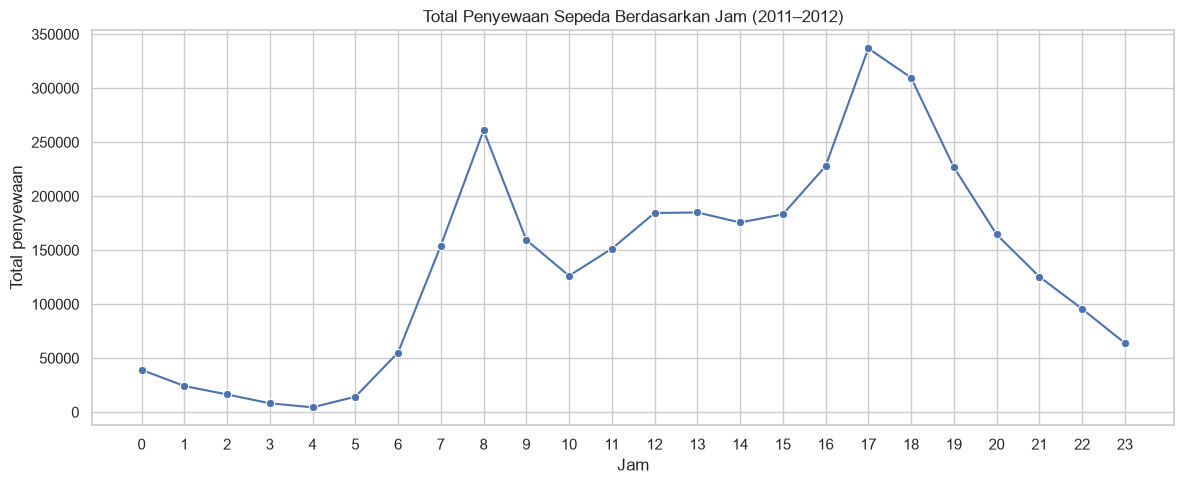

Jam tertinggi: 17:00 — 336,860
Jam terendah: 04:00 — 4,428


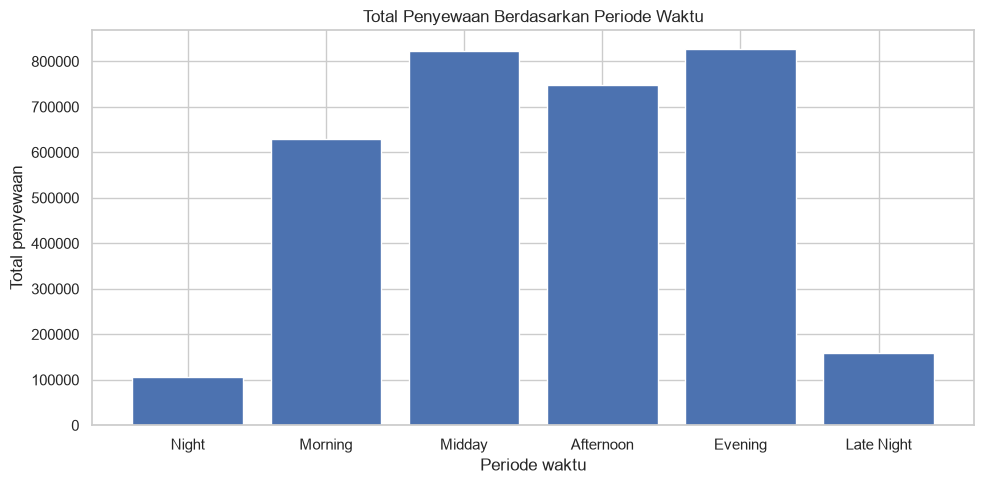

In [23]:
plt.figure(figsize=(12, 5))
sns.lineplot(data=hourly_rental, x="hr", y="total_rentals", marker="o")
plt.title("Total Penyewaan Sepeda Berdasarkan Jam (2011–2012)")
plt.xlabel("Jam"); plt.ylabel("Total penyewaan"); plt.xticks(range(24))
plt.tight_layout(); plt.show()

peak_hour = hourly_rental.loc[hourly_rental["total_rentals"].idxmax()]
lowest_hour = hourly_rental.loc[hourly_rental["total_rentals"].idxmin()]
print(f"Jam tertinggi: {int(peak_hour['hr']):02d}:00 — {peak_hour['total_rentals']:,.0f}")
print(f"Jam terendah: {int(lowest_hour['hr']):02d}:00 — {lowest_hour['total_rentals']:,.0f}")

plt.figure(figsize=(10, 5))
period_plot = period_rental.assign(time_period=period_rental["time_period"].astype(str))
plt.bar(period_plot["time_period"], period_plot["total_rentals"])
plt.title("Total Penyewaan Berdasarkan Periode Waktu")
plt.xlabel("Periode waktu"); plt.ylabel("Total penyewaan")
plt.tight_layout(); plt.show()

**Explanatory insight — Pertanyaan 1**

Pukul **17.00** merupakan jam dengan total penyewaan tertinggi, yaitu **336.860**, sedangkan pukul **04.00** merupakan jam terendah, yaitu **4.428**. Periode **Evening** mencatat total tertinggi (**826.556**) dan **Night** terendah (**106.509**). Pola ini dapat menjadi dasar awal untuk mengatur ketersediaan sepeda pada jam sibuk; keputusan penempatan tetap perlu mempertimbangkan lokasi.

### Pertanyaan 2: Bagaimana rata-rata penyewaan sepeda per jam berbeda berdasarkan musim dan kondisi cuaca selama periode 2011–2012, dan kategori mana yang memiliki rata-rata tertinggi dan terendah?

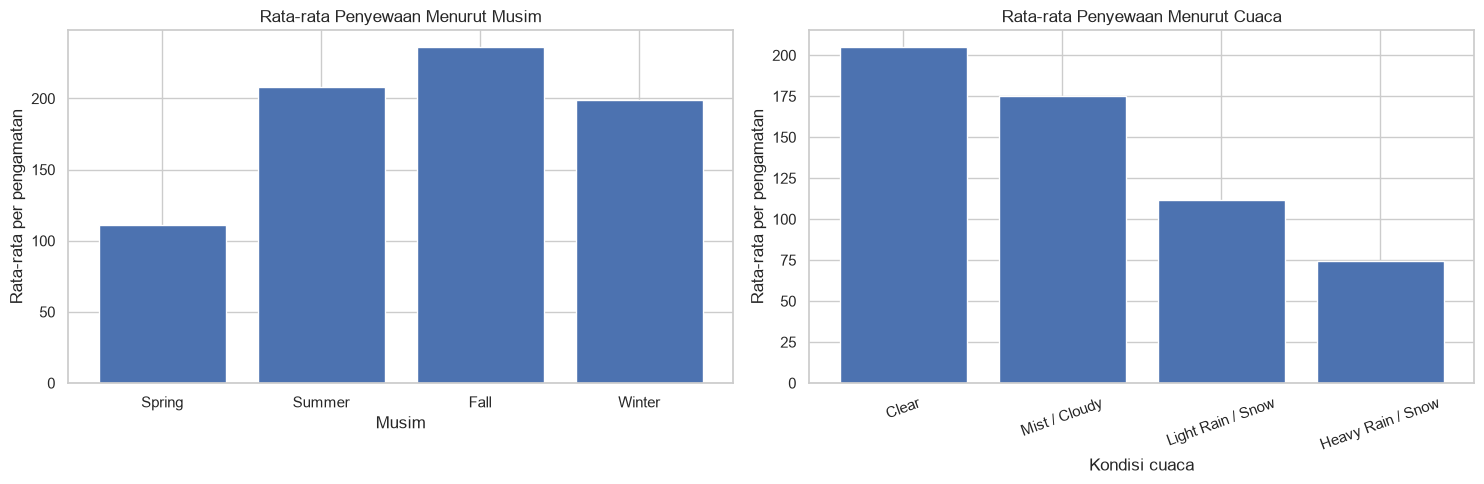

Musim tertinggi: Fall (236.02)
Musim terendah: Spring (111.11)
Cuaca tertinggi: Clear (204.87)
Cuaca terendah: Heavy Rain / Snow (74.33)
\nJumlah observasi cuaca:


,weather_label,observations,average_rentals
0,Clear,11413,204.869272
3,Mist / Cloudy,4544,175.165493
2,Light Rain / Snow,1419,111.579281
1,Heavy Rain / Snow,3,74.333333


In [24]:
season_summary["season_label"] = pd.Categorical(season_summary["season_label"], categories=season_order, ordered=True)
season_summary = season_summary.sort_values("season_label")
weather_summary["weather_label"] = pd.Categorical(weather_summary["weather_label"], categories=weather_order, ordered=True)
weather_summary = weather_summary.sort_values("weather_label")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(season_summary["season_label"].astype(str), season_summary["average_rentals"])
axes[0].set(title="Rata-rata Penyewaan Menurut Musim", xlabel="Musim", ylabel="Rata-rata per pengamatan")
axes[1].bar(weather_summary["weather_label"].astype(str), weather_summary["average_rentals"])
axes[1].set(title="Rata-rata Penyewaan Menurut Cuaca", xlabel="Kondisi cuaca", ylabel="Rata-rata per pengamatan")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

for label, summary in [("musim", season_summary), ("cuaca", weather_summary)]:
    hi = summary.loc[summary["average_rentals"].idxmax()]
    lo = summary.loc[summary["average_rentals"].idxmin()]
    category = "season_label" if label == "musim" else "weather_label"
    print(f"{label.title()} tertinggi: {hi[category]} ({hi['average_rentals']:.2f})")
    print(f"{label.title()} terendah: {lo[category]} ({lo['average_rentals']:.2f})")
print("\\nJumlah observasi cuaca:")
display(weather_summary[["weather_label", "observations", "average_rentals"]])

**Explanatory insight — Pertanyaan 2**

Musim **Fall** memiliki rata-rata penyewaan tertinggi (sekitar **236,02** per pengamatan), sedangkan **Spring** terendah (sekitar **111,12**). Berdasarkan cuaca, **Clear** memiliki rata-rata tertinggi (sekitar **204,87**) dan **Heavy Rain / Snow** terendah (sekitar **74,33**). Namun, kategori Heavy Rain / Snow hanya memiliki **3 observasi**, sehingga hasil tersebut tidak cukup kuat untuk digeneralisasi. Hasil ini menunjukkan pola/asosiasi, bukan bukti sebab-akibat.

## Analisis Lanjutan (Opsional)

### Heatmap rata-rata penyewaan berdasarkan kombinasi musim dan cuaca

Heatmap digunakan untuk mengeksplorasi kombinasi kategori. Rata-rata dipilih agar perbandingan tidak hanya dipengaruhi oleh perbedaan jumlah observasi.

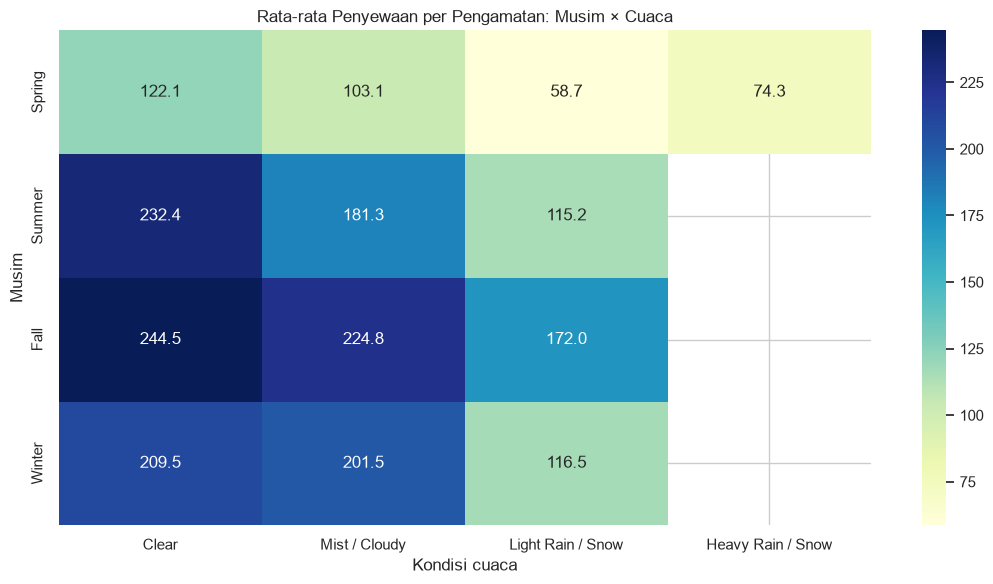

weather_label,Clear,Mist / Cloudy,Light Rain / Snow,Heavy Rain / Snow
season_label,,,,
Spring,122.055535,103.074689,58.650407,74.333333
Summer,232.410983,181.261364,115.179803,NaN
Fall,244.494207,224.848997,171.955390,NaN
Winter,209.463779,201.483974,116.453333,NaN


In [25]:
season_weather_avg = (df_clean.groupby(["season_label", "weather_label"])["cnt"].mean()
    .unstack().reindex(index=season_order, columns=weather_order))
plt.figure(figsize=(11, 6))
sns.heatmap(season_weather_avg, annot=True, fmt=".1f", cmap="YlGnBu")
plt.title("Rata-rata Penyewaan per Pengamatan: Musim × Cuaca")
plt.xlabel("Kondisi cuaca"); plt.ylabel("Musim")
plt.tight_layout(); plt.show()
display(season_weather_avg)

**Insight analisis lanjutan**
- Heatmap membantu melihat kombinasi musim dan cuaca yang memiliki rata-rata penyewaan relatif tinggi atau rendah.
- Kategori dengan observasi sangat sedikit harus ditafsirkan hati-hati.
- Analisis ini eksploratif; untuk mengukur pengaruh independen musim dan cuaca diperlukan analisis statistik lanjutan.

## Conclusion & Recommendation

### Conclusion
1. **Pertanyaan 1 — Pola waktu:** Jam dengan total penyewaan tertinggi adalah pukul **17.00** (336.860), sedangkan terendah pukul **04.00** (4.428). Periode **Evening** tertinggi (826.556), sedangkan **Night** terendah (106.509). Permintaan tidak merata sepanjang hari.
2. **Pertanyaan 2 — Musim dan cuaca:** Rata-rata tertinggi menurut musim terjadi pada **Fall** (sekitar 236,02), terendah pada **Spring** (sekitar 111,12). Menurut cuaca, **Clear** tertinggi (sekitar 204,87), sementara **Heavy Rain / Snow** terendah (sekitar 74,33); kategori terakhir hanya memiliki tiga observasi sehingga kesimpulannya terbatas.

### Recommendation / Action Items
1. **Perencanaan jam sibuk:** Pantau ketersediaan unit menjelang jam dengan permintaan tinggi, terutama sekitar 07.00–09.00 dan 16.00–19.00. Validasi dengan data lokasi stasiun sebelum redistribusi.
2. **Perencanaan musiman:** Gunakan tren musiman sebagai salah satu masukan untuk jadwal perawatan dan ketersediaan unit.
3. **Kondisi cuaca:** Pantau prakiraan cuaca dan siapkan prosedur operasional yang sesuai; jangan membuat keputusan besar berdasarkan kategori Heavy Rain / Snow saja karena observasinya sangat sedikit.
4. **Evaluasi berkala:** Gunakan dashboard interaktif untuk memantau pola jam, musim, dan cuaca dengan data operasional terbaru.

**Catatan:** Temuan menggambarkan data historis 2011–2012 dan perlu divalidasi dengan data terkini sebelum diterapkan.